https://arxiv.org/pdf/1312.5602

paper original DQN

https://arxiv.org/pdf/1707.06347

paper original ppo

# Pac-Man simplificado + PPO

Contenido del notebook:
1. Entorno `PacmanEnv` (Gymnasium) donde **vos diseñás el mapa** como una grilla de texto.
2. Entrenamiento con **PPO** (Stable-Baselines3).
3. Gráficos de aprendizaje, evaluación y animación del agente jugando.

**Reglas del juego**
- 1 Pac-Man y 1 fantasma. El fantasma persigue por el camino más corto con probabilidad `ghost_chase_prob` y, si no, se mueve al azar.
- El episodio termina si: Pac-Man se come **todas** las bolitas (gana), el fantasma lo atrapa (pierde) o se llega a `max_steps` (truncado).


In [ ]:
!pip install -q gymnasium stable-baselines3 matplotlib

In [ ]:
import numpy as np
import gymnasium as gym
from gymnasium import spaces
from collections import deque

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.evaluation import evaluate_policy

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 1. Diseñá tu mapa

Cada carácter es una celda:

| Símbolo | Significado |
|---|---|
| `#` | pared |
| `.` | bolita |
| `P` | posición inicial de Pac-Man (exactamente una) |
| `G` | posición inicial del fantasma (exactamente una) |
| ` ` (espacio) | celda libre sin bolita |

Todas las filas deben tener el mismo largo. Conviene rodear el mapa con paredes.


In [ ]:
MAPA = [
    "###########",
    "#P....#...#",
    "#.###.#.#.#",
    "#.#.....#.#",
    "#.#.###.#.#",
    "#...#G#...#",
    "#.###.###.#",
    "#.........#",
    "###########",
]

## 2. El entorno

- **Acciones:** 0 = arriba, 1 = abajo, 2 = izquierda, 3 = derecha (si choca con una pared, se queda quieto).
- **Observación:** 4 canales aplanados (paredes, bolitas, Pac-Man, fantasma), valores 0/1.
- **Recompensas** (editables): `+1` por bolita, `-0.01` por paso, `-0.05` por chocar contra pared, `+10` por ganar, `-10` si lo atrapa el fantasma.


In [ ]:
class PacmanEnv(gym.Env):
    metadata = {"render_modes": ["rgb_array", "ansi"], "render_fps": 4}
    MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]  # arriba, abajo, izquierda, derecha

    def __init__(self, mapa, max_steps=200, ghost_chase_prob=0.7, render_mode=None,
                 r_pellet=1.0, r_step=-0.05, r_wall=-0.1, r_win=10.0, r_dead=-10.0):
        super().__init__()
        filas = [list(f) for f in mapa]
        if len({len(f) for f in filas}) != 1:
            raise ValueError("Todas las filas del mapa deben tener el mismo largo.")
        grid = np.array(filas)
        if (grid == "P").sum() != 1:
            raise ValueError("El mapa debe tener exactamente una 'P'.")
        if (grid == "G").sum() != 1:
            raise ValueError("El mapa debe tener exactamente una 'G'.")
        if (grid == ".").sum() == 0:
            raise ValueError("El mapa necesita al menos una bolita '.'.")

        self.H, self.W = grid.shape
        self.walls = grid == "#"
        self.pellets_init = grid == "."
        self.pac_start = tuple(int(x) for x in np.argwhere(grid == "P")[0])
        self.ghost_start = tuple(int(x) for x in np.argwhere(grid == "G")[0])

        self.max_steps = max_steps
        self.ghost_chase_prob = ghost_chase_prob
        self.render_mode = render_mode
        self.r_pellet, self.r_step, self.r_wall = r_pellet, r_step, r_wall
        self.r_win, self.r_dead = r_win, r_dead

        self.action_space = spaces.Discrete(4)
        self.observation_space = spaces.Box(0.0, 1.0, shape=(4 * self.H * self.W,), dtype=np.float32)

    # ---------- utilidades ----------
    def _free(self, r, c):
        return 0 <= r < self.H and 0 <= c < self.W and not self.walls[r, c]

    def _obs(self):
        pac = np.zeros((self.H, self.W), np.float32); pac[self.pac] = 1.0
        gh = np.zeros((self.H, self.W), np.float32); gh[self.ghost] = 1.0
        return np.concatenate([
            self.walls.astype(np.float32).ravel(),
            self.pellets.astype(np.float32).ravel(),
            pac.ravel(), gh.ravel(),
        ])

    def _bfs(self, origen):
        """Distancia (en pasos) desde `origen` a cada celda alcanzable."""
        dist = np.full((self.H, self.W), np.inf)
        dist[origen] = 0
        q = deque([origen])
        while q:
            r, c = q.popleft()
            for dr, dc in self.MOVES:
                nr, nc = r + dr, c + dc
                if self._free(nr, nc) and dist[nr, nc] == np.inf:
                    dist[nr, nc] = dist[r, c] + 1
                    q.append((nr, nc))
        return dist

    def _move_ghost(self):
        r, c = self.ghost
        vecinos = [(r + dr, c + dc) for dr, dc in self.MOVES if self._free(r + dr, c + dc)]
        if not vecinos:
            return
        if self.np_random.random() < self.ghost_chase_prob:
            dist = self._bfs(self.pac)
            mejor = min(dist[v] for v in vecinos)
            candidatos = [v for v in vecinos if dist[v] == mejor]
        else:
            candidatos = vecinos
        self.ghost = candidatos[self.np_random.integers(len(candidatos))]

    # ---------- API Gymnasium ----------
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.pac = self.pac_start
        self.ghost = self.ghost_start
        self.pellets = self.pellets_init.copy()
        self.t = 0
        return self._obs(), {"pellets_left": int(self.pellets.sum())}

    def step(self, action):
        self.t += 1
        reward = self.r_step
        terminated = truncated = False
        win = caught = False

        # 1) movimiento de Pac-Man
        dr, dc = self.MOVES[int(action)]
        old_pac, old_ghost = self.pac, self.ghost
        nr, nc = old_pac[0] + dr, old_pac[1] + dc
        if self._free(nr, nc):
            self.pac = (nr, nc)
        else:
            reward += self.r_wall

        # 2) comer bolita
        if self.pellets[self.pac]:
            self.pellets[self.pac] = False
            reward += self.r_pellet

        if self.pellets.sum() == 0:           # ganó (tiene prioridad sobre el fantasma)
            reward_remaining = self.max_steps - self.t
            reward += self.r_win + reward_remaining * 0.1
            terminated = win = True
        elif self.pac == self.ghost:          # Pac-Man caminó hacia el fantasma
            caught = True
        else:
            # 3) movimiento del fantasma
            self._move_ghost()
            if self.pac == self.ghost or (self.pac == old_ghost and self.ghost == old_pac):
                caught = True                 # incluye cruzarse "de frente"

        if caught:
            reward += self.r_dead
            terminated = True

        if not terminated and self.t >= self.max_steps:
            truncated = True

        info = {"pellets_left": int(self.pellets.sum()), "win": win, "caught": caught}
        return self._obs(), reward, terminated, truncated, info

    # ---------- render ----------
    def render(self):
        if self.render_mode == "ansi":
            filas = []
            for r in range(self.H):
                fila = ""
                for c in range(self.W):
                    if (r, c) == self.pac: fila += "P"
                    elif (r, c) == self.ghost: fila += "G"
                    elif self.walls[r, c]: fila += "#"
                    elif self.pellets[r, c]: fila += "."
                    else: fila += " "
                filas.append(fila)
            return "\n".join(filas)
        return self._draw_rgb()

    def _draw_rgb(self, S=32):
        img = np.zeros((self.H * S, self.W * S, 3), np.uint8)
        yy, xx = np.mgrid[0:S, 0:S]
        circ = lambda rad: (yy - S / 2 + .5) ** 2 + (xx - S / 2 + .5) ** 2 <= rad ** 2
        big, small = circ(S * 0.38), circ(S * 0.12)
        for r in range(self.H):
            for c in range(self.W):
                tile = img[r * S:(r + 1) * S, c * S:(c + 1) * S]   # vista, escribe sobre img
                if self.walls[r, c]:
                    tile[:] = (33, 33, 222)
                elif self.pellets[r, c]:
                    tile[small] = (255, 255, 255)
                if (r, c) == self.pac:
                    tile[big] = (255, 221, 0)
                if (r, c) == self.ghost:
                    tile[big] = (255, 40, 40)
        return img

### Prueba rápida del entorno
Verifica que cumple con la API de Gymnasium y juega una partida con acciones al azar.


In [ ]:
env = PacmanEnv(MAPA, render_mode="ansi")
check_env(env, warn=True)

obs, info = env.reset(seed=0)
print(env.render(), "\n")
total, done = 0, False
while not done:
    obs, r, term, trunc, info = env.step(env.action_space.sample())
    total += r
    done = term or trunc
print(env.render())
print(f"\nPasos: {env.t} | recompensa: {total:.2f} | info: {info}")


###########
#P....#...#
#.###.#.#.#
#.#.....#.#
#.#.###.#.#
#...#G#...#
#.###.###.#
#.........#
########### 

###########
# ....#...#
#P###.#.#.#
# #.....#.#
# #.###.#.#
#...# #...#
#.###.###.#
#.........#
###########

Pasos: 19 | recompensa: -8.75 | info: {'pellets_left': 37, 'win': False, 'caught': True}


## 3. Entrenamiento con PPO

Usamos 8 entornos en paralelo. Un `callback` guarda la recompensa y si ganó o no cada episodio, para graficar después.
Para mapas más grandes o más difíciles, subí `TOTAL_TIMESTEPS`.



Entrenando con max_steps = 10


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



Entrenando con max_steps = 50

Entrenando con max_steps = 60

Entrenando con max_steps = 75

Entrenando con max_steps = 85

Entrenando con max_steps = 100

Entrenando con max_steps = 150

Entrenando con max_steps = 200

Entrenando con max_steps = 300


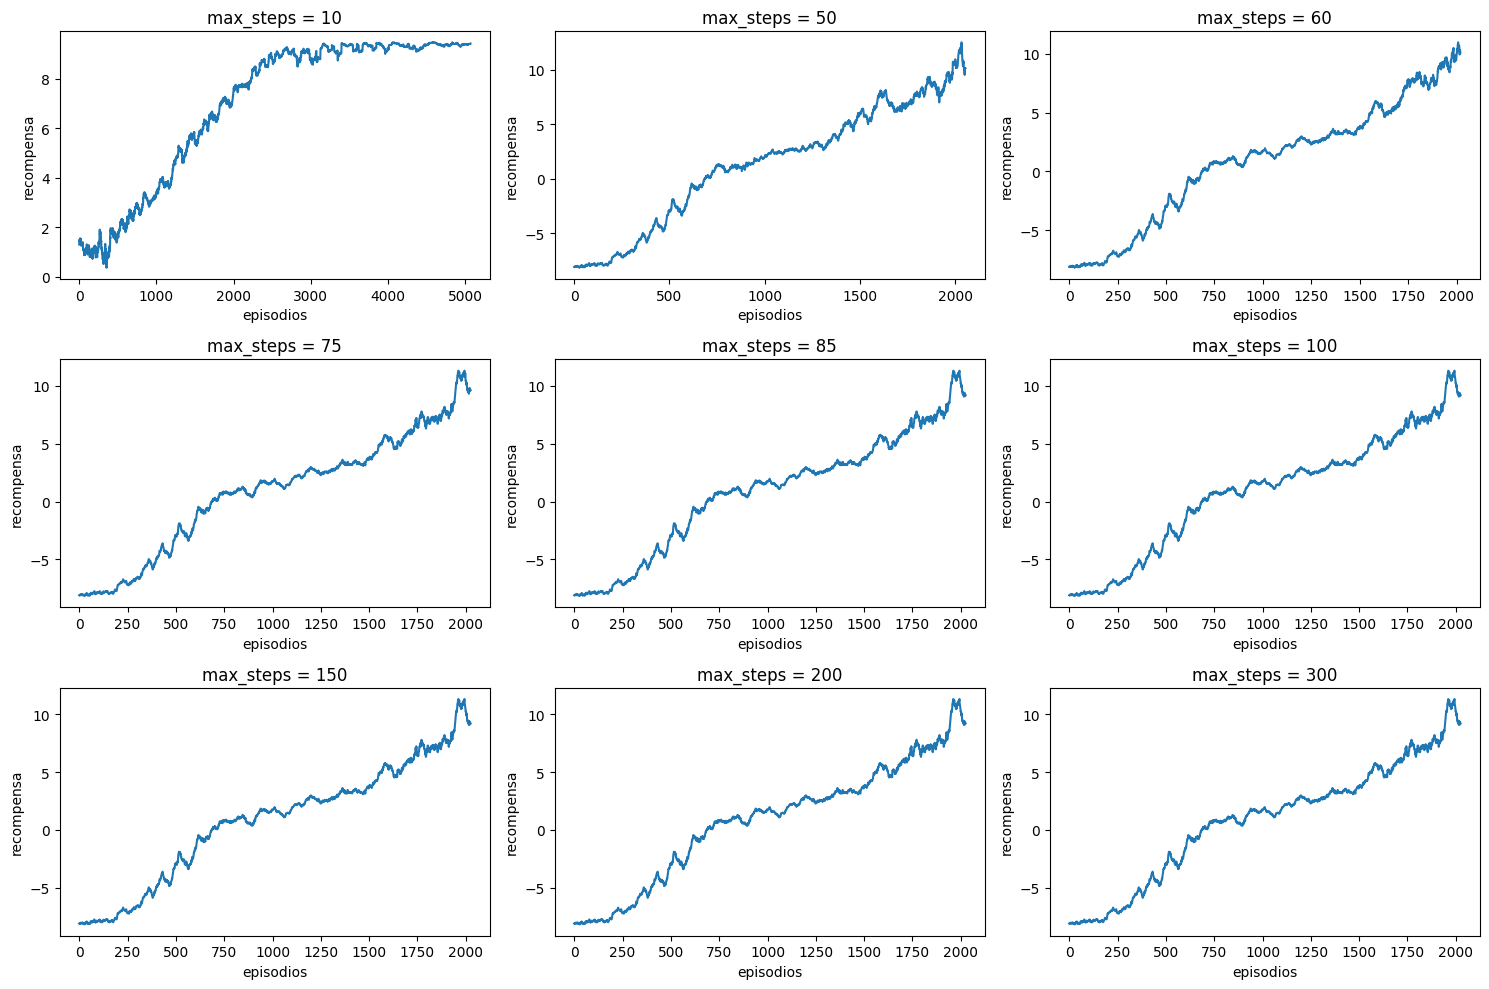

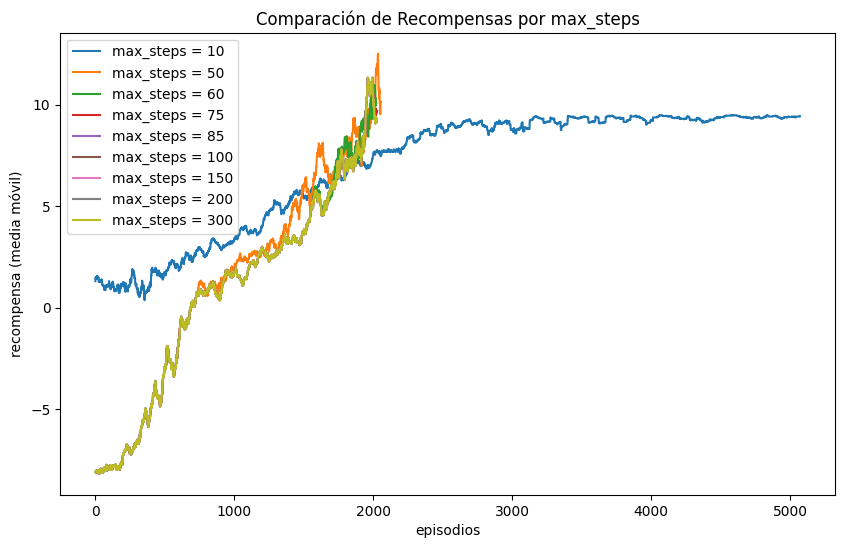

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3 import PPO

# Definir variables y utilidades necesarias localmente
GHOST_CHASE_PROB = 0.7

class LogCallback(BaseCallback):
    def __init__(self):
        super().__init__()
        self.rewards, self.wins, self.caught = [], [], []

    def _on_step(self):
        for info, done in zip(self.locals["infos"], self.locals["dones"]):
            if done:
                self.rewards.append(info["episode"]["r"])
                self.wins.append(float(info["win"]))
                self.caught.append(float(info["caught"]))
        return True

def media_movil(x, k=100):
    x = np.asarray(x, dtype=float)
    if len(x) == 0: return x
    k = min(k, len(x))
    return np.convolve(x, np.ones(k) / k, mode="valid")

max_steps_list = [10, 50, 60, 75, 85, 100, 150, 200, 300]
results = {}

for ms in max_steps_list:
    print(f"\nEntrenando con max_steps = {ms}")
    def make_env_ms():
        return PacmanEnv(MAPA, max_steps=ms, ghost_chase_prob=GHOST_CHASE_PROB)

    vec_env_ms = make_vec_env(make_env_ms, n_envs=8, seed=0)

    model_ms = PPO(
        "MlpPolicy", vec_env_ms,
        learning_rate=3e-4,
        n_steps=256,
        batch_size=256,
        n_epochs=10,
        gamma=0.99,
        gae_lambda=0.95,
        clip_range=0.2,
        ent_coef=0.01,
        policy_kwargs=dict(net_arch=[128, 128]),
        device="cpu",
        verbose=0,
        seed=0,
    )

    log_ms = LogCallback()
    model_ms.learn(total_timesteps=50_000, callback=log_ms)
    results[ms] = log_ms.rewards

# Plot individual
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()
for i, ms in enumerate(max_steps_list):
    axes[i].plot(media_movil(results[ms], k=50))
    axes[i].set_title(f"max_steps = {ms}")
    axes[i].set_xlabel("episodios")
    axes[i].set_ylabel("recompensa")
plt.tight_layout()
plt.show()

# Plot comparativo
plt.figure(figsize=(10, 6))
for ms in max_steps_list:
    plt.plot(media_movil(results[ms], k=50), label=f"max_steps = {ms}")
plt.title("Comparación de Recompensas por max_steps")
plt.xlabel("episodios")
plt.ylabel("recompensa (media móvil)")
plt.legend()
plt.show()

In [1]:
TRAIN_MAPS = [
    # Mapa original
    [
        "###########",
        "#P....#...#",
        "#.###.#.#.#",
        "#.#.....#.#",
        "#.#.###.#.#",
        "#...#G#...#",
        "#.###.###.#",
        "#.........#",
        "###########",
    ],
    # Mapa de pasillos largos
    [
        "###########",
        "#P........#",
        "#.#######.#",
        "#.........#",
        "#.#######.#",
        "#......G..#",
        "###########",
    ],
    # Mapa tipo laberinto cerrado
    [
        "#########",
        "#P#...#.#",
        "#.#.#.#.#",
        "#...#...#",
        "#.###.#.#",
        "#......G#",
        "#########",
    ],
    # Mapa 15x12 (15 filas x 12 columnas)
    [
        "############",
        "#P.........#",
        "#.###.####.#",
        "#.#......#.#",
        "#.#.####.#.#",
        "#.#......#.#",
        "#.####.###.#",
        "#..........#",
        "#.###..###.#",
        "#.#......#.#",
        "#.#.####.#.#",
        "#.#......#.#",
        "#.####.###.#",
        "#.........G#",
        "############",
    ],
    # Mapa 6x7 (6 filas x 7 columnas)
    [
        "#######",
        "#P....#",
        "#.###.#",
        "#.#G#.#",
        "#.....#",
        "#######",
    ]
]

TEST_MAPS = [
    # Mapa de prueba 1: Abierto con obstáculos centrales
    [
        "#############",
        "#P..........#",
        "#.###.###.#.#",
        "#.#.....#.#.#",
        "#.#.###.#.#.#",
        "#.........G.#",
        "#############",
    ],
    # Mapa de prueba 2: Zig-zag
    [
        "###########",
        "#...#...#.#",
        "#.P.#.#.#.#",
        "#.#...#...#",
        "#.###.###.#",
        "#G........#",
        "###########",
    ],
    # Mapa 14x20 (14 filas x 20 columnas)
    [
        "####################",
        "#P.................#",
        "#.####.#######.###.#",
        "#.#..............#.#",
        "#.#.####.###.###.#.#",
        "#.#.#..........#.#.#",
        "#.#.#.########.#.#.#",
        "#.#.#........G.#.#.#",
        "#.#.##########.#.#.#",
        "#.#..............#.#",
        "#.####.#######.###.#",
        "#..................#",
        "#.################.#",
        "####################",
    ]
]

print(f"Mapas de entrenamiento definidos: {len(TRAIN_MAPS)}")
print(f"Mapas de prueba (inéditos) definidos: {len(TEST_MAPS)}")

Mapas de entrenamiento definidos: 5
Mapas de prueba (inéditos) definidos: 3


In [ ]:
MAX_STEPS = 100
GHOST_CHASE_PROB = 0.7
TOTAL_TIMESTEPS = 400_000

def make_env():
    return PacmanEnv(MAPA, max_steps=MAX_STEPS, ghost_chase_prob=GHOST_CHASE_PROB)

class LogCallback(BaseCallback):
    def __init__(self):
        super().__init__()
        self.rewards, self.wins, self.caught = [], [], []

    def _on_step(self):
        for info, done in zip(self.locals["infos"], self.locals["dones"]):
            if done:
                self.rewards.append(info["episode"]["r"])
                self.wins.append(float(info["win"]))
                self.caught.append(float(info["caught"]))
        return True

vec_env = make_vec_env(make_env, n_envs=8, seed=0)

model = PPO(
    "MlpPolicy", vec_env,
    learning_rate=3e-4,
    n_steps=256,          # por entorno -> 256*8 = 2048 transiciones por update
    batch_size=256,
    n_epochs=10,
    gamma=0.99,
    gae_lambda=0.95,
    clip_range=0.2,
    ent_coef=0.01,        # bonus de entropía: favorece la exploración
    policy_kwargs=dict(net_arch=[128, 128]),
    device="cpu",         # para una MLP chica la CPU alcanza y sobra
    verbose=1,
    seed=0,
)

log = LogCallback()
model.learn(total_timesteps=TOTAL_TIMESTEPS, callback=log)

Using cuda device


/usr/local/lib/python3.13/dist-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 17       |
|    ep_rew_mean     | -7.78    |
| time/              |          |
|    fps             | 1744     |
|    iterations      | 1        |
|    time_elapsed    | 1        |
|    total_timesteps | 2048     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 18.8        |
|    ep_rew_mean          | -7.71       |
| time/                   |             |
|    fps                  | 1504        |
|    iterations           | 2           |
|    time_elapsed         | 2           |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.015097766 |
|    clip_fraction        | 0.122       |
|    clip_range           | 0.2         |
|    entropy_loss         | -1.38       |
|    explained_variance   | -0.0201     |
|    learning_rate        | 0.

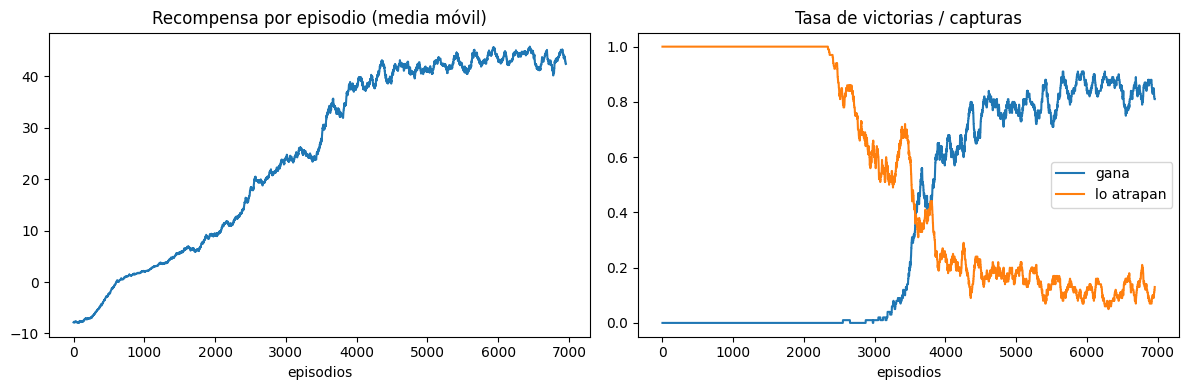

In [ ]:
def media_movil(x, k=100):
    x = np.asarray(x, dtype=float)
    k = min(k, len(x))
    return np.convolve(x, np.ones(k) / k, mode="valid")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(media_movil(log.rewards)); ax[0].set_title("Recompensa por episodio (media móvil)")
ax[0].set_xlabel("episodios")
ax[1].plot(media_movil(log.wins), label="gana")
ax[1].plot(media_movil(log.caught), label="lo atrapan")
ax[1].set_title("Tasa de victorias / capturas"); ax[1].set_xlabel("episodios"); ax[1].legend()
plt.tight_layout(); plt.show()

## 4. Evaluación

In [ ]:
def evaluar(model, n=200, deterministic=False):
    env = make_env()
    wins = caught = timeouts = 0
    pasos = []
    for i in range(n):
        obs, _ = env.reset(seed=1000 + i)
        done = False
        while not done:
            a, _ = model.predict(obs, deterministic=deterministic)
            obs, r, term, trunc, info = env.step(int(a))
            done = term or trunc
        wins += info["win"]; caught += info["caught"]; timeouts += (trunc and not term)
        pasos.append(env.t)
    print(f"Victorias: {wins/n:.1%} | Capturas: {caught/n:.1%} | Timeouts: {timeouts/n:.1%} | Pasos medios: {np.mean(pasos):.1f}")

evaluar(model, deterministic=False)
evaluar(model, deterministic=True)

Victorias: 90.0% | Capturas: 7.5% | Timeouts: 2.5% | Pasos medios: 73.5
Victorias: 95.0% | Capturas: 3.5% | Timeouts: 1.5% | Pasos medios: 74.4


## 5. Ver al agente jugar
Si con `deterministic=True` el agente se queda en un bucle, probá con `False`.


In [ ]:
def jugar_episodio(model, deterministic=False, seed=None):
    env = PacmanEnv(MAPA, max_steps=MAX_STEPS, ghost_chase_prob=GHOST_CHASE_PROB, render_mode="rgb_array")
    obs, _ = env.reset(seed=seed)
    frames = [env.render()]
    done = False
    while not done:
        a, _ = model.predict(obs, deterministic=deterministic)
        obs, r, term, trunc, info = env.step(int(a))
        frames.append(env.render())
        done = term or trunc
    return frames, info

def animar(frames, intervalo=250):
    fig, ax = plt.subplots(figsize=(frames[0].shape[1] / 64, frames[0].shape[0] / 64))
    ax.axis("off")
    im = ax.imshow(frames[0])
    def update(i):
        im.set_data(frames[i]); return [im]
    anim = FuncAnimation(fig, update, frames=len(frames), interval=intervalo, blit=True)
    plt.close(fig)
    return HTML(anim.to_jshtml())

frames, info = jugar_episodio(model, deterministic=True, seed=42)
print(info, "| pasos:", len(frames) - 1)
animar(frames)

{'pellets_left': 0, 'win': True, 'caught': False} | pasos: 87


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 6. Guardar / cargar el modelo

In [ ]:
#model.save("ppo_pacman")
# model = PPO.load("ppo_pacman", device="cpu")

# En Colab, para descargarlo:
# from google.colab import files
# files.download("ppo_pacman.zip")